# Can Monkeys beat Cap-Weighted portfolios ?

The idea is to repeatedly generate **random portfolios given the universe of stocks** each year throught the period of time.

## Data and Experimental Design

### Data

The analysis uses monthly U.S. equity data from the **CRSP CIZ Monthly Stock File**, obtained with the help of **WRDS**. The period covered is **January 2000 to December 2025**.

The main variables used are:

- `PERMNO` — permanent CRSP security identifier (Ticker may change)
- `Ticker` — ticker symbol
- `MthCalDt` — calendar month
- `MthRet` — monthly total return
- `MthPrevCap` — lagged market capitalization
- `MthDelFlg` — monthly delisting flag

---

### Investable Universe

The stock universe is reconstructed separately at the beginning of every calendar year from **2000 through 2025**.

For each year:

1. January observations are selected.
2. Stocks are ranked by `MthPrevCap`.
3. The **1,000 largest stocks by lagged market capitalization** form the universe for the year.
   
---

### Random ("Monkey") Portfolios

The experiment follows the random-portfolio idea motivated by **Clare, Motson & Thomas (2013)**.

The randomness enters only through **portfolio allocation**. Clearlt, the underlying stock returns are actual historical CRSP returns.

---

### Monte Carlo Simulation

The procedure of picking stocks is repeated for **1,000,000** times.

In total, the experiment therefore generates:

**1,000,000 portfolio paths × 26 annual random allocations** .

---

### Capitalization-Weighted Benchmark

A capitalization-weighted portfolio is constructed using the same annual top-1,000 universes - prepared data.

---

### Computational Note: Batch Processing

Running millions of portfolio simulations at once would require too much memory. Instead, the simulations can be processed in **batches**.

For example:

$$
10{,}000{,}000
=
1000 \times 10{,}000
$$

In [376]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd 
import numpy as np 
import sys
sys.path.append("..")

from src import data_toolkit as dt
from src import portfolio_toolkit as pt
from pathlib import Path
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Data Preparation

The sample is restricted to securities classified by CRSP as **common stocks (`SecuritySubType = COM`)**.

In [377]:
df = pd.read_csv("../data/processed/8000stocks.csv")
df = df[df['SecuritySubType']=='COM']

In [378]:
bad_stocks = df.loc[
    df[["MthPrevCap", "MthRet"]].isna().any(axis=1),
    "PERMNO"
].unique()

good_stocks = df[~df["PERMNO"].isin(bad_stocks)]
good_stocks[["MthPrevCap", "MthRet"]].isna().sum()

MthPrevCap    0
MthRet        0
dtype: int64

In [135]:
good_stocks

,PERMNO,HdrCUSIP,SecuritySubType,Ticker,PERMCO,MthCalDt,MthDelFlg,MthPrevCap,MthRet,month
0,10001,36720410,COM,EWST,7953,2000-01-31,N,2.082500e+04,-0.044118,2000-01
1,10001,36720410,COM,EWST,7953,2000-02-29,N,1.990625e+04,0.015385,2000-02
2,10001,36720410,COM,EWST,7953,2000-03-31,N,2.021250e+04,-0.015288,2000-03
3,10001,36720410,COM,EWST,7953,2000-04-28,N,1.971200e+04,0.011719,2000-04
4,10001,36720410,COM,EWST,7953,2000-05-31,N,1.994300e+04,-0.023166,2000-05
...,...,...,...,...,...,...,...,...,...,...
2423207,93436,88160R10,COM,TSLA,53453,2025-08-29,N,9.943092e+08,0.083044,2025-08
2423208,93436,88160R10,COM,TSLA,53453,2025-09-30,N,1.076881e+09,0.332015,2025-09
2423209,93436,88160R10,COM,TSLA,53453,2025-10-31,N,1.478249e+09,0.026623,2025-10
2423210,93436,88160R10,COM,TSLA,53453,2025-11-28,N,1.518436e+09,-0.057802,2025-11


Let's inspect the data on internal gaps: 

In [185]:
good_stocks["MthCalDt"] = pd.to_datetime(good_stocks["MthCalDt"])
def has_gap(x):
    x = x.dt.to_period("M")
    expected = pd.period_range(x.min(), x.max(), freq="M")
    return x.nunique() != len(expected)

gaps = good_stocks.groupby("PERMNO")["MthCalDt"].apply(has_gap)

gaps.value_counts()

MthCalDt
False    16047
True         1
Name: count, dtype: int64

One security with an internal gap in its monthly history can be excluded from the sample.

In [187]:
bad_permno = gaps[gaps].index[0]

good_stocks = good_stocks[
    good_stocks["PERMNO"] != bad_permno
].copy()

good_stocks.groupby("PERMNO")["MthCalDt"].apply(has_gap).value_counts()

MthCalDt
False    16047
Name: count, dtype: int64

### Delisting Flag

`MthDelFlg` indicates whether a monthly return is associated with a delisting event.

- `N` — no delisting
- `A`, `P`, `V` — delisting return is incorporated into `MthRet`
- `M`, `G` — delisting occurred, but the delisting return is not fully incorporated

For the simulation, `MthRet` is used up to the final observed month. If a stock disappears afterwards, the remaining position is treated as cash until the next annual rebalance.

#### Final Observation per Security

`last_rows` contains the **last available monthly observation for each PERMNO** in the cleaned CRSP sample.

This will help us decide how to treat stocks that disappear during a holding year in the Monte Carlo simulation.

In [379]:
last_rows = (
    good_stocks
    .sort_values("MthCalDt")
    .groupby("PERMNO")
    .tail(1)
)

last_rows["MthDelFlg"].value_counts()

MthDelFlg
N    14713
A     1071
P      223
M       32
V        8
G        1
Name: count, dtype: int64

### Identifying the biggest 1000 stocks

In [190]:
top1000_df = pd.DataFrame()

for year in range(2000, 2026):
    jan = good_stocks[
        (good_stocks["MthCalDt"].dt.year == year) &
        (good_stocks["MthCalDt"].dt.month == 1)
    ]

    top1000 = jan.nlargest(1000, "MthPrevCap")
    permnos = top1000["PERMNO"]

    yearly_data = good_stocks[
        (good_stocks["MthCalDt"].dt.year == year) &
        (good_stocks["PERMNO"].isin(permnos))
    ]

    top1000_df = pd.concat([top1000_df, yearly_data])

In [191]:
top1000_df

,PERMNO,HdrCUSIP,SecuritySubType,Ticker,PERMCO,MthCalDt,MthDelFlg,MthPrevCap,MthRet
3203,10078,86681020,COM,SUNW,8021,2000-01-31,N,1.208881e+08,0.014528
3204,10078,86681020,COM,SUNW,8021,2000-02-29,N,1.226444e+08,0.212411
3205,10078,86681020,COM,SUNW,8021,2000-03-31,N,1.486953e+08,-0.016240
3206,10078,86681020,COM,SUNW,8021,2000-04-28,N,1.486519e+08,-0.018843
3207,10078,86681020,COM,SUNW,8021,2000-05-31,N,1.460543e+08,-0.166553
...,...,...,...,...,...,...,...,...,...
2423207,93436,88160R10,COM,TSLA,53453,2025-08-29,N,9.943092e+08,0.083044
2423208,93436,88160R10,COM,TSLA,53453,2025-09-30,N,1.076881e+09,0.332015
2423209,93436,88160R10,COM,TSLA,53453,2025-10-31,N,1.478249e+09,0.026623
2423210,93436,88160R10,COM,TSLA,53453,2025-11-28,N,1.518436e+09,-0.057802


### What is the stock does not have 12 data points in a given year ?
I would like to avoid look ahead bias - I wil not pick those stocks that survive.
```
Instead, we will hold such stocks anyway. After the stock disappears, whatever value that position has becomes cash from the next month. The other stocks' weights are not changed.
```

Portfolio weights are assigned at the beginning of each year and will remain fixed until the next annual rebalance.

If a selected stock disappears during the year:

- actual `MthRet` values are used up to its final observed month;
- if `MthDelFlg = A` or `P`, the final `MthRet` already incorporates the delisting return;
- if `MthDelFlg = N`, the stock is assumed to be liquidated at its last observed value;
- for all remaining months of that year, the position receives a `0%` return and is **treated as cash**;
- position's weight is not redistributed to the remaining stocks.

#### Identifying how many stocks disappeared throughout the year

In [196]:
counts = (
    top1000_df
    .groupby([top1000_df["MthCalDt"].dt.year, "PERMNO"])
    .size()
)

incomplete = counts[counts < 12]
last_in_year = (
    top1000_df
    .assign(year=top1000_df["MthCalDt"].dt.year)
    .sort_values("MthCalDt")
    .groupby(["year", "PERMNO"])
    .tail(1)
    .set_index(["year", "PERMNO"])
)

incomplete_last = last_in_year.loc[incomplete.index]

incomplete_last["MthDelFlg"].value_counts()

MthDelFlg
N    694
A    120
P      3
Name: count, dtype: int64

In [335]:
top1000_df =[]
for year in range(2000, 2026):

    # Top 1000 at the beginning of the year
    jan = good_stocks[
        (good_stocks["MthCalDt"].dt.year == year) &
        (good_stocks["MthCalDt"].dt.month == 1)
    ].nlargest(1000, "MthPrevCap")

    permnos = jan["PERMNO"]

    # January market cap for each selected stock
    jan_caps = jan[
        ["PERMNO", "MthPrevCap"]
    ].copy()

    # Actual observations during the year
    yearly = good_stocks[
        (good_stocks["MthCalDt"].dt.year == year) &
        (good_stocks["PERMNO"].isin(permnos))
    ][["PERMNO", "Ticker", "MthCalDt", "MthRet", "MthDelFlg"]]

    # Full 1000 x 12 structure
    months = pd.date_range(
        f"{year}-01-01",
        f"{year}-12-31",
        freq="ME"
    )

    grid = pd.MultiIndex.from_product(
        [permnos, months],
        names=["PERMNO", "MthCalDt"]
    ).to_frame(index=False)

    yearly = grid.merge(
        yearly,
        on=["PERMNO", "MthCalDt"],
        how="left"
    )

    # Add beginning-of-year market cap
    yearly = yearly.merge(
        jan_caps,
        on="PERMNO",
        how="left"
    )

    # After disappearance -> cash
    yearly["MthRet"] = yearly["MthRet"].fillna(0)

    top1000_df.append(yearly)

top1000_df = pd.concat(top1000_df, ignore_index=True)

This is our prepared data

In [336]:
len(top1000_df)

312000

In [229]:
top1000_df['MthCalDt'] = top1000_df['MthCalDt'].dt.to_period('M')

That is, 1000 * 12 * 26 (years) = 312 000 rows - CORRECT !

In [233]:
top1000_df.to_csv("../data/processed/1000stocks_adjusted.csv")

## 2. Monkey's Portfolio: Year 2000 - 2025
Let's first construct one series of portfolio returns. 

In [264]:
rets_test = []

for year in range(2000,2026):
    
    rets_stocks =(
    top1000_df[top1000_df["MthCalDt"].dt.year == year]
    .pivot(index="MthCalDt", columns="PERMNO", values="MthRet")
    )
    
    draws = np.random.choice(rets_stocks.columns, size=1000, replace=True)

    weights = (pd.Series(draws).value_counts().reindex(rets_stocks.columns, fill_value=0)/ 1000)

    
    rets_test.append(rets_stocks @ weights)
    
rets_test = pd.concat(rets_test)

<Axes: title={'center': "1 Monkey's Portfolio"}, xlabel='MthCalDt'>

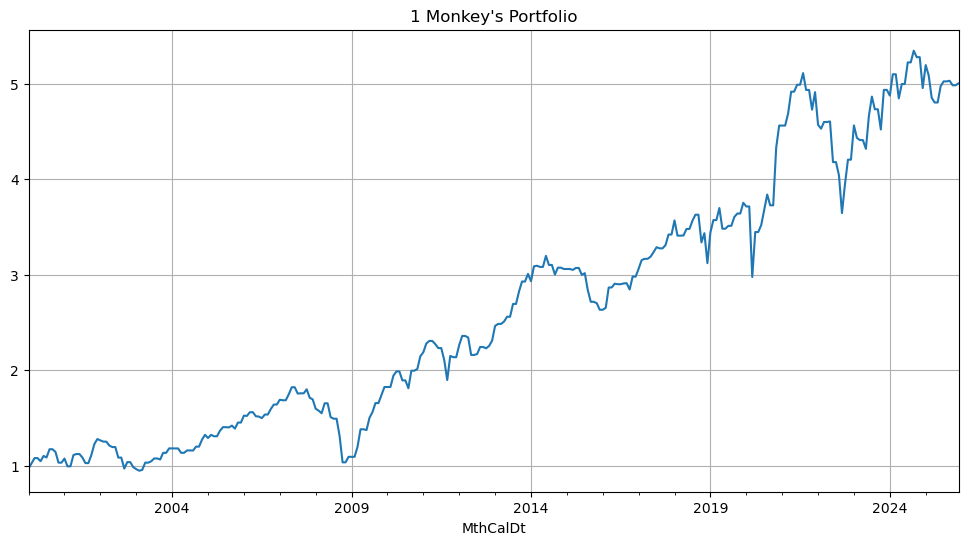

In [263]:
(rets_test+1).cumprod().plot(figsize = (12,6), title = "1 Monkey's Portfolio", grid = True)

Not bad at all !

### From 1 Monkey to Million: Monte Carlo Simulation

We simulate one million complete portfolio histories. Each simulated portfolio receives a new random allocation at every annual rebalance.

> **Each year, one monkey looks at the 1,000 largest stocks and makes 1,000 random draws with replacement; those draws determine that year’s portfolio weights. The monkey repeats this every year from 2000 to 2025, producing one complete 25-year portfolio history. Then we create 1,000,000 monkeys and let each of them independently repeat the same 25-year process. The result is a distribution of 1,000,000 full portfolio outcomes, which we compare with EW and CW.**

#### Test run on 10 000 simulations

In [274]:
n_sims = 10000

draws = np.random.choice(rets_stocks.columns,size=(n_sims, 1000),replace=True)
weights = np.zeros((n_sims, 1000))

for i in range(n_sims):
    
    counts = pd.Series(draws[i]).value_counts()
    
    weights[i] = (counts.reindex(rets_stocks.columns, fill_value=0).values/ 1000)
    
monkey_rets = rets_stocks.values @ weights.T

In [272]:
all_monkey_rets = []

for year in range(2000, 2026):

    rets_stocks = (
        top1000_df[top1000_df["MthCalDt"].dt.year == year]
        .pivot(index="MthCalDt", columns="PERMNO", values="MthRet")
    )

    draws = np.random.choice(
        rets_stocks.columns,
        size=(n_sims, 1000),
        replace=True
    )

    weights = np.zeros((n_sims, 1000))

    for i in range(n_sims):
        counts = pd.Series(draws[i]).value_counts()
        weights[i] = (
            counts
            .reindex(rets_stocks.columns, fill_value=0)
            .values / 1000
        )

    monkey_rets = rets_stocks.values @ weights.T

    all_monkey_rets.append(
        pd.DataFrame(
            monkey_rets,
            index=rets_stocks.index
        )
    )

all_monkey_rets = pd.concat(all_monkey_rets)

In [273]:
all_monkey_rets

,0,1,2,3,4,5,6,7,8,9,...,9990,9991,9992,9993,9994,9995,9996,9997,9998,9999
MthCalDt,,,,,,,,,,,,,,,,,,,,,
2000-01,-0.043196,-0.032476,-0.037828,-0.038374,-0.043589,-0.035291,-0.044136,-0.041127,-0.037924,-0.030493,...,-0.030061,-0.028538,-0.042316,-0.032249,-0.036629,-0.037993,-0.031636,-0.039828,-0.040207,-0.032353
2000-02,0.061726,0.067620,0.043871,0.059886,0.058300,0.045506,0.052207,0.054300,0.064806,0.046149,...,0.057283,0.077747,0.068519,0.060804,0.057322,0.061814,0.071828,0.072302,0.061988,0.066264
2000-03,0.045641,0.052984,0.054226,0.053136,0.057343,0.042303,0.052235,0.058111,0.049002,0.058317,...,0.044322,0.051937,0.035486,0.043291,0.047871,0.051694,0.051329,0.049250,0.034528,0.050700
2000-04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2000-05,-0.026486,-0.018981,-0.024313,-0.020988,-0.029084,-0.029676,-0.018249,-0.021150,-0.031311,-0.021452,...,-0.032078,-0.024841,-0.025352,-0.027746,-0.027421,-0.023047,-0.018621,-0.032731,-0.034266,-0.021876
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-08,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2025-09,0.008294,0.003069,0.004167,0.006953,0.012999,0.007983,0.008431,0.012152,0.009102,0.010697,...,0.007127,0.006375,0.007666,0.012082,0.007747,0.008778,0.005754,0.005076,0.005689,0.011542
2025-10,-0.003577,-0.010299,-0.013342,-0.008632,-0.006475,-0.007869,-0.005926,-0.008559,-0.000400,-0.005547,...,-0.007601,-0.010170,-0.011395,-0.006667,-0.013645,-0.007640,-0.006845,-0.009351,-0.008325,-0.001137


<Axes: title={'center': '10,000 Monkeys Cum. Performance'}, ylabel='Frequency'>

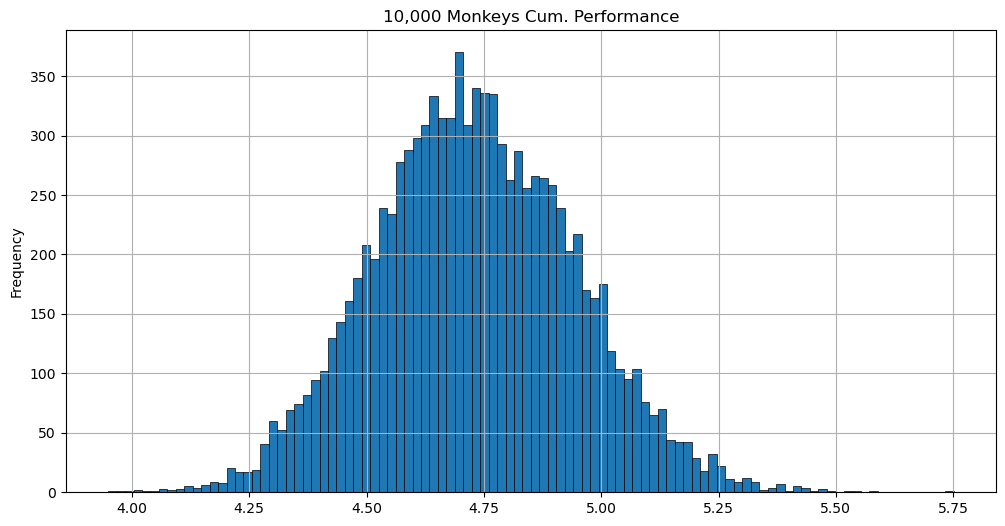

In [302]:
terminal_wealth = (1 + all_monkey_rets).prod()
terminal_wealth.plot.hist(bins = 100, grid = True, figsize = (12,6), title = '10,000 Monkeys Cum. Performance',
                         edgecolor="black",linewidth=0.5)

download risk-free rate history:

In [291]:
rf = dt.get_fff_returns()['RF'].loc['2000-01':'2025-12']
rf

Date
2000-01    0.0041
2000-02    0.0043
2000-03    0.0047
2000-04    0.0046
2000-05    0.0050
            ...  
2025-08    0.0038
2025-09    0.0033
2025-10    0.0037
2025-11    0.0030
2025-12    0.0034
Freq: M, Name: RF, Length: 312, dtype: float64

compute one full-sample Sharpe ratio per monkey path:

In [292]:
sr = all_monkey_rets.aggregate(pt.sharpe_ratio,riskfree_rate=rf,periods_per_year=12)

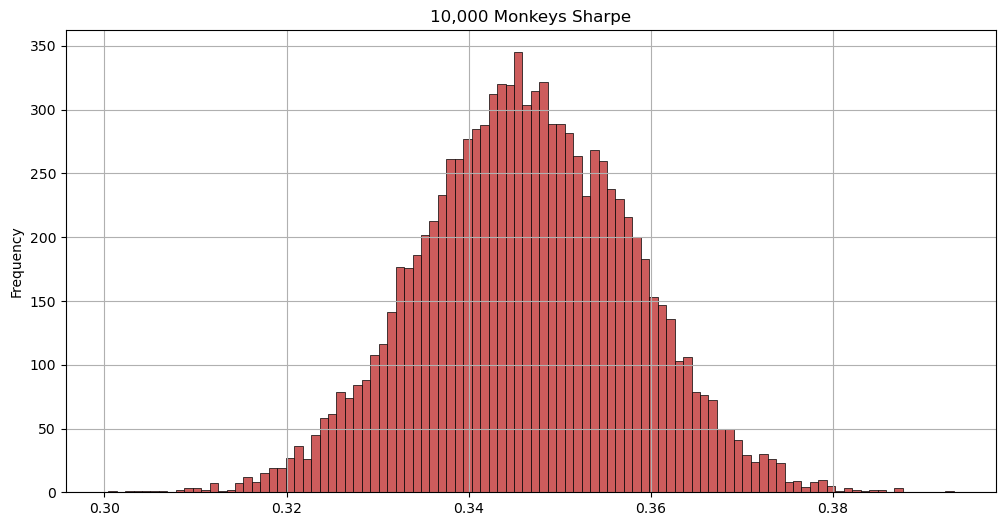

In [307]:
ax = sr.plot.hist(bins = 100, grid = True, figsize = (12,6), title = '10,000 Monkeys Sharpe', 
             color = 'indianred', edgecolor="black",linewidth=0.5)

### Final: 1,000,000 Monkeys

In [305]:
import time

n_sims = 1_000_000
batch_size = 10_000
n_batches = n_sims // batch_size

all_sr = []
all_terminal_wealth = []

start = time.time()

for batch in range(n_batches):
    
    batch_start = time.time()
    all_monkey_rets = []

    for year in range(2000, 2026):

        rets_stocks = (top1000_df[top1000_df["MthCalDt"].dt.year == year].pivot(index="MthCalDt", columns="PERMNO", values="MthRet"))

        draws = np.random.choice(rets_stocks.columns,size=(batch_size, 1000),replace=True)

        weights = np.zeros((batch_size, 1000))

        for i in range(batch_size):
            
            counts = pd.Series(draws[i]).value_counts()

            weights[i] = (counts.reindex(rets_stocks.columns, fill_value=0).values / 1000)

        
        monkey_rets = rets_stocks.values @ weights.T
        all_monkey_rets.append(pd.DataFrame(monkey_rets,index=rets_stocks.index))

    all_monkey_rets = pd.concat(all_monkey_rets)
    sr_batch = all_monkey_rets.aggregate(pt.sharpe_ratio, riskfree_rate=rf, periods_per_year=12)

    terminal_wealth_batch = (1 + all_monkey_rets).prod()

    all_sr.append(sr_batch)
    all_terminal_wealth.append(terminal_wealth_batch)

    elapsed = time.time() - start
    avg_batch_time = elapsed / (batch + 1)
    remaining = avg_batch_time * (n_batches - batch - 1)

    print(
        f"Batch {batch + 1}/{n_batches} | "
        f"{(batch + 1) * batch_size:,} monkeys | "
        f"batch: {(time.time() - batch_start)/60:.2f} min | "
        f"elapsed: {elapsed/60:.1f} min | "
        f"remaining: {remaining/60:.1f} min"
    )

sr_1m = pd.concat(all_sr, ignore_index=True)

terminal_wealth_1m = pd.concat(
    all_terminal_wealth,
    ignore_index=True
)

Batch 1/100 | 10,000 monkeys | batch: 0.73 min | elapsed: 0.7 min | remaining: 72.0 min
Batch 2/100 | 20,000 monkeys | batch: 0.76 min | elapsed: 1.5 min | remaining: 73.1 min
Batch 3/100 | 30,000 monkeys | batch: 0.70 min | elapsed: 2.2 min | remaining: 70.7 min
Batch 4/100 | 40,000 monkeys | batch: 0.76 min | elapsed: 3.0 min | remaining: 70.8 min
Batch 5/100 | 50,000 monkeys | batch: 0.76 min | elapsed: 3.7 min | remaining: 70.5 min
Batch 6/100 | 60,000 monkeys | batch: 0.76 min | elapsed: 4.5 min | remaining: 70.1 min
Batch 7/100 | 70,000 monkeys | batch: 0.78 min | elapsed: 5.3 min | remaining: 69.8 min
Batch 8/100 | 80,000 monkeys | batch: 0.68 min | elapsed: 5.9 min | remaining: 68.2 min
Batch 9/100 | 90,000 monkeys | batch: 0.67 min | elapsed: 6.6 min | remaining: 66.8 min
Batch 10/100 | 100,000 monkeys | batch: 0.78 min | elapsed: 7.4 min | remaining: 66.5 min
Batch 11/100 | 110,000 monkeys | batch: 0.73 min | elapsed: 8.1 min | remaining: 65.7 min
Batch 12/100 | 120,000 monke

#### Describing Results:

In [312]:
len(sr_1m), len(terminal_wealth_1m)

(1000000, 1000000)

In [311]:
sr_1m.describe(), terminal_wealth_1m.describe()

(count    1000000.000000
 mean           0.346298
 std            0.011525
 min            0.292782
 25%            0.338523
 50%            0.346284
 75%            0.354066
 max            0.403980
 dtype: float64,
 count    1000000.000000
 mean           4.728938
 std            0.214283
 min            3.810892
 25%            4.582110
 50%            4.723859
 75%            4.870641
 max            5.943477
 dtype: float64)

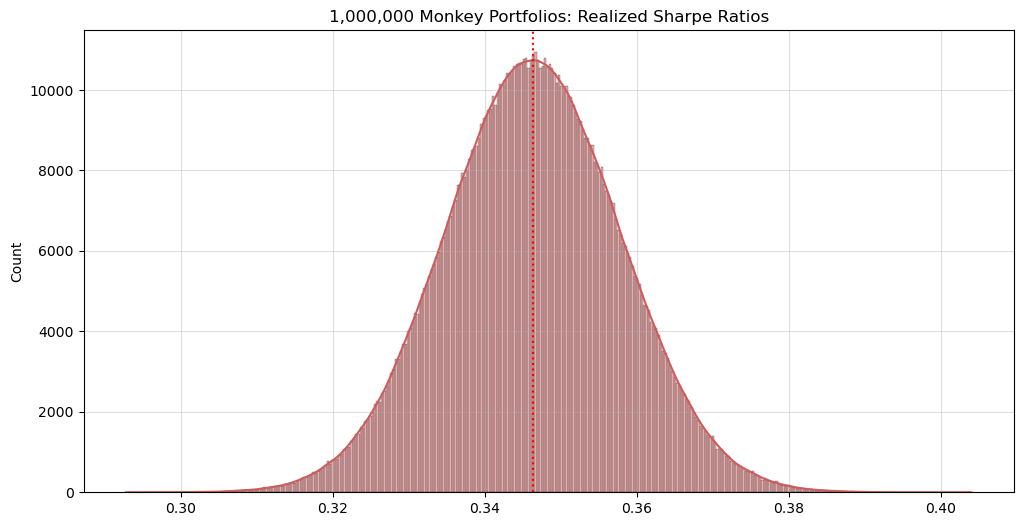

In [328]:
import seaborn as sns
plt.figure(figsize = (12,6))
plt.title('1,000,000 Monkey Portfolios: Realized Sharpe Ratios')
plt.grid(alpha = 0.4)
sns.histplot(sr_1m, color = 'indianred', kde = True)
plt.axvline(sr_1m.mean(), ls = ':', color = 'red')

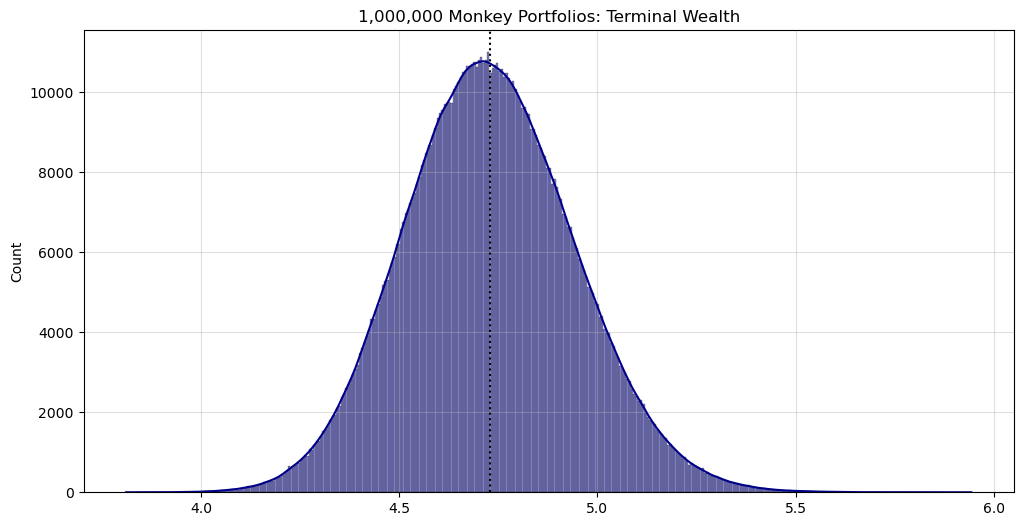

In [342]:
plt.figure(figsize = (12,6))
plt.title('1,000,000 Monkey Portfolios: Terminal Wealth')
plt.grid(alpha = 0.4)
sns.histplot(terminal_wealth_1m, color = 'darkblue', kde = True)
plt.axvline(terminal_wealth_1m.mean(), ls = ':', color = 'black')

## 3. Monkeys vs. Caw-Weighted Portfolio

Fisrt, lets construct CW portfolio.

In [337]:
top1000_df

,PERMNO,MthCalDt,Ticker,MthRet,MthDelFlg,MthPrevCap
0,10107,2000-01-31,MSFT,-0.161670,N,6.024329e+08
1,10107,2000-02-29,MSFT,-0.086845,N,6.024329e+08
2,10107,2000-03-31,MSFT,0.188811,N,6.024329e+08
3,10107,2000-04-30,NaN,0.000000,NaN,6.024329e+08
4,10107,2000-05-31,MSFT,-0.103047,N,6.024329e+08
...,...,...,...,...,...,...
311995,15651,2025-08-31,NaN,0.000000,NaN,5.922101e+06
311996,15651,2025-09-30,CSW,-0.112561,N,5.922101e+06
311997,15651,2025-10-31,CSW,0.032709,N,5.922101e+06
311998,15651,2025-11-30,NaN,0.000000,NaN,5.922101e+06


In [355]:
cw_rets = []

for year in range(2000, 2026):

    rets_stocks = (
        top1000_df[top1000_df["MthCalDt"].dt.year == year]
        .pivot(index="MthCalDt", columns="PERMNO", values="MthRet")
    )
    ## Previous Month Cap for January
    jan_mc = (
        top1000_df[
            (top1000_df["MthCalDt"].dt.year == year) &
            (top1000_df["MthCalDt"].dt.month == 1)
        ]
        .set_index("PERMNO")["MthPrevCap"]
        .reindex(rets_stocks.columns)
    )

    weights = jan_mc / jan_mc.sum()

    rets = rets_stocks.values @ weights.values

    cw_rets.append(
        pd.Series(
            rets,
            index=rets_stocks.index
        )
    )

cw_rets = pd.concat(cw_rets)
cw_rets.index=cw_rets.index.to_period('M')

In [362]:
cw_tw = (cw_rets+1).prod()
cw_sr = pt.sharpe_ratio(cw_rets, rf, 12)

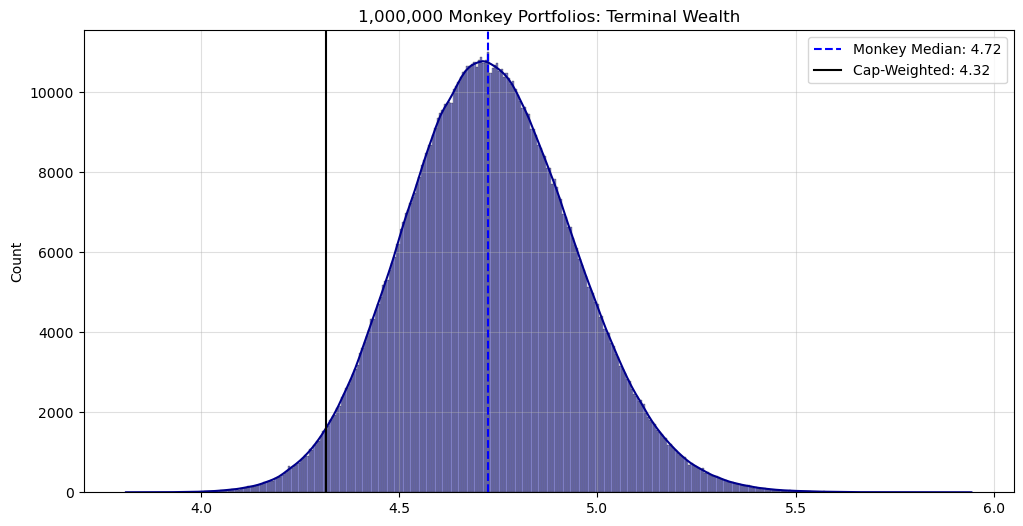

In [382]:
plt.figure(figsize=(12,6))
plt.title('1,000,000 Monkey Portfolios: Terminal Wealth')
plt.grid(alpha=0.4)

sns.histplot(
    terminal_wealth_1m,
    color='darkblue',
    kde=True
)

plt.axvline(
    terminal_wealth_1m.median(),
    ls='--',
    color='blue',
    label=f'Monkey Median: {terminal_wealth_1m.median():.2f}'
)

plt.axvline(
    cw_tw,
    color='black',
    label=f'Cap-Weighted: {cw_tw:.2f}'
)

plt.legend()
plt.show()

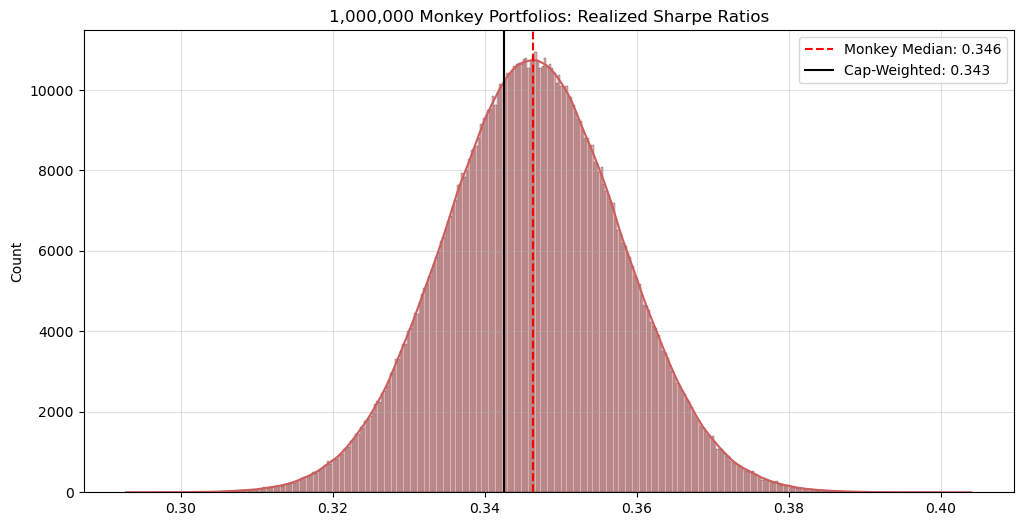

In [381]:
plt.figure(figsize=(12,6))
plt.title('1,000,000 Monkey Portfolios: Realized Sharpe Ratios')
plt.grid(alpha=0.4)

sns.histplot(sr_1m,color='indianred',kde=True)

plt.axvline(
    sr_1m.median(),
    ls='--',
    color='red',
    label=f'Monkey Median: {sr_1m.median():.3f}'
)

plt.axvline(cw_sr,color='black',label=f'Cap-Weighted: {cw_sr:.3f}')

plt.legend()
plt.show()

In [371]:
monkeys_beating_cw = (terminal_wealth_1m > cw_tw).mean() * 100
print(f"Monkeys beating CW in TW: {monkeys_beating_cw:.2f}%")

Monkeys beating CW in TW: 97.72%


In [373]:
monkeys_beating_cw = (sr_1m > cw_sr).mean() * 100
print(f"Monkeys beating CW in SR: {monkeys_beating_cw:.2f}%")

Monkeys beating CW in SR: 62.85%


### Comparison with Capitalization Weighting

The capitalization-weighted benchmark performs poorly relative to the distribution of randomly weighted portfolios.

- **97.72%** of the one million monkey portfolios achieve higher terminal wealth than CW.
- **62.85%** achieve a higher realized Sharpe ratio than CW.

So, the result is particularly strong for terminal wealth: almost the entire distribution of random portfolios generated by our monkeys outperforms capitalization weighting over the sample period.